# 01 · Exploración de la OBT (EDA)

**Qué predice el modelo y cuándo.** Las ventas diarias no negativas (`UNIT_SALES_TARGET`) de cada
tienda–producto perecedero, para cada uno de los **16 días** posteriores a una fecha de corte. En el
momento de predecir solo se conoce la historia hasta el corte y lo que se planifica de antemano
(calendario, feriados, promociones).

**Dos fuentes, una sola tabla.**

- Tamaño, tipos, faltantes y estadística del objetivo: sobre la **OBT completa** en Snowflake
  (`PSET2_DB.ANALYTICS.OBT_SALES`, 13.017.002 filas), con consultas agregadas.
- Gráficos, atípicos y correlaciones: sobre la **muestra de 2.000 series** de `src/datos.py`
  (estratificada por familia, semilla 42, huella SHA-256 verificada al cargar). Es la misma muestra
  con la que se entrenan todos los modelos.

Al final, la sección 8 resume los hallazgos con su evidencia y su consecuencia en el modelo.

In [1]:
import json
import sys
import warnings

sys.path.insert(0, '..')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from src.datos import cargar_muestra, consultar, tabla_obt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

FIGURAS = '../docs/figuras'
# Paleta de referencia (guía de visualización): azul/naranja para dos grupos,
# rampa azul para magnitud y divergente azul–gris–rojo para correlaciones.
AZUL, NARANJA, ROJO, GRIS = '#2a78d6', '#eb6834', '#e34948', '#f0efec'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'
DIVERGENTE = LinearSegmentedColormap.from_list('div', [AZUL, GRIS, ROJO])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b8b7b0',
    'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

OBT = tabla_obt()
OBJETIVO = 'UNIT_SALES_TARGET'
SERIE = ['STORE_NBR', 'ITEM_NBR']

ventas, meta = cargar_muestra()
ventas = ventas.sort_values(SERIE + ['DATE']).reset_index(drop=True)
y = ventas[OBJETIVO]
print(json.dumps({k: v for k, v in meta.items() if k != 'series_por_familia'}, indent=1, ensure_ascii=False))
print('Series por familia en la muestra:', meta['series_por_familia'])

{
 "tabla_origen": "PSET2_DB.ANALYTICS.OBT_SALES",
 "filas_obt": 13017002,
 "fecha_min": "2016-08-01",
 "fecha_corte_snapshot": "2017-08-15",
 "obt_last_altered": "2026-11-14 10:27:32.033000-08:00",
 "extraido_utc": "2026-11-16T00:16:10+00:00",
 "series_elegibles": 37545,
 "n_series": 2000,
 "semilla_muestra": 42,
 "fecha_limite_historia": "2017-06-15",
 "filas_muestra": 692950,
 "sha256": "4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee2a4deb035538e899cc"
}
Series por familia en la muestra: {'BREAD/BAKERY': 257, 'DAIRY': 559, 'DELI': 212, 'EGGS': 73, 'MEATS': 114, 'POULTRY': 110, 'PREPARED FOODS': 62, 'PRODUCE': 599, 'SEAFOOD': 14}


## 1. Tamaño, tipos de datos y faltantes (OBT completa)

Cada columna se clasifica según su **papel**: no todas pueden ser variables del modelo. Las marcas de
auditoría del PSet 2 y las columnas de procedencia revelan el objetivo o no tienen significado
predictivo, y las transacciones y el petróleo del mismo día no existen al predecir.

In [2]:
columnas = consultar('''
    SELECT COLUMN_NAME AS "columna", DATA_TYPE AS "tipo"
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'ANALYTICS' AND TABLE_NAME = 'OBT_SALES'
    ORDER BY ORDINAL_POSITION''')
conteo = consultar('SELECT COUNT(*) AS "FILAS", '
                   + ', '.join(f'COUNT_IF("{c}" IS NULL) AS "{c}"' for c in columnas['columna'])
                   + f' FROM {OBT}')
FILAS_OBT = int(conteo.pop('FILAS').iloc[0])

ROLES = {
    'clave': ['DATE_KEY', 'STORE_KEY', 'ITEM_KEY', 'DATE', 'STORE_NBR', 'ITEM_NBR'],
    'objetivo': ['UNIT_SALES_TARGET'],
    'no usar: revela el objetivo': ['ID', 'UNIT_SALES_ORIGINAL', 'UNIT_SALES_SOURCE_TEXT', 'IS_RETURN',
                                    'IS_OBSERVED', 'IS_IMPUTED_ZERO', 'IS_ONPROMOTION_IMPUTED',
                                    'IS_AFTER_LAST_SALE'],
    'no usar: procedencia': ['SOURCE_FILE', 'SOURCE_ROW_NUMBER', 'LOAD_BATCH_ID', 'SOURCE_SHA256',
                             'TRANSACTIONS_SOURCE_FILE', 'TRANSACTIONS_SOURCE_ROW_NUMBER',
                             'TRANSACTIONS_LOAD_BATCH_ID', 'OIL_PRICE_REFERENCE_DATE', 'OIL_PRICE_AGE_DAYS',
                             'OIL_HAS_SOURCE_ROW', 'OIL_IS_SOURCE_PRICE_MISSING', 'OIL_IS_IMPUTED'],
    'no disponible al predecir (mismo día)': ['TRANSACTIONS_OBSERVED', 'HAS_TRANSACTIONS',
                                              'IS_TRANSACTIONS_MISSING', 'OIL_PRICE_OBSERVED',
                                              'OIL_PRICE_PREPARED'],
}
rol_de = {c: rol for rol, cols in ROLES.items() for c in cols}
tabla_columnas = columnas.assign(
    faltantes=[int(conteo[c].iloc[0]) for c in columnas['columna']],
    rol=[rol_de.get(c, 'conocida al predecir') for c in columnas['columna']],
)
tabla_columnas['pct_faltantes'] = 100 * tabla_columnas['faltantes'] / FILAS_OBT
print(f'OBT: {FILAS_OBT:,} filas x {len(columnas)} columnas')
print(tabla_columnas['tipo'].value_counts().to_string())
tabla_columnas

OBT: 13,017,002 filas x 57 columnas
tipo
NUMBER     23
BOOLEAN    21
TEXT       11
DATE        2


,columna,tipo,faltantes,rol,pct_faltantes
0,ID,NUMBER,3083717,no usar: revela el objetivo,23.6899
1,DATE_KEY,NUMBER,0,clave,0.0000
2,STORE_KEY,NUMBER,0,clave,0.0000
3,ITEM_KEY,NUMBER,0,clave,0.0000
4,UNIT_SALES_ORIGINAL,NUMBER,3083717,no usar: revela el objetivo,23.6899
5,UNIT_SALES_TARGET,NUMBER,0,objetivo,0.0000
6,UNIT_SALES_SOURCE_TEXT,TEXT,3083717,no usar: revela el objetivo,23.6899
7,IS_RETURN,BOOLEAN,0,no usar: revela el objetivo,0.0000
8,ONPROMOTION,BOOLEAN,0,conocida al predecir,0.0000
9,IS_ONPROMOTION_IMPUTED,BOOLEAN,0,no usar: revela el objetivo,0.0000


In [3]:
# ¿Los faltantes de ID / UNIT_SALES_ORIGINAL coinciden exactamente con los ceros reconstruidos?
consultar(f'''
    SELECT COUNT_IF(IS_IMPUTED_ZERO)                       AS "ceros_reconstruidos",
           COUNT_IF(ID IS NULL)                            AS "id_nulo",
           COUNT_IF(ID IS NULL AND NOT IS_IMPUTED_ZERO)    AS "id_nulo_no_reconstruido",
           COUNT_IF(TRANSACTIONS_OBSERVED IS NULL)         AS "transacciones_nulas",
           COUNT_IF(OIL_PRICE_OBSERVED IS NULL)            AS "petroleo_observado_nulo",
           COUNT_IF(OIL_PRICE_PREPARED IS NULL)            AS "petroleo_preparado_nulo"
    FROM {OBT}''')

,ceros_reconstruidos,id_nulo,id_nulo_no_reconstruido,transacciones_nulas,petroleo_observado_nulo,petroleo_preparado_nulo
0,3083717,3083717,0,1470,4009247,0


**Lectura.**

- Los 3.083.717 nulos de `ID`, `UNIT_SALES_ORIGINAL` y las columnas de procedencia son **exactamente**
  los ceros reconstruidos del panel (PSet 2): no hay registro fuente porque `train.csv` omite las
  ventas cero. Son nulos **por diseño**, no información perdida, y esas columnas no entran al modelo.
- `EVENT_DESCRIPTIONS` es nula en los días sin evento (texto libre). Los conteos y marcas de eventos
  ya resumen esa información.
- `OIL_PRICE_OBSERVED` es nula en fines de semana y feriados; `OIL_PRICE_PREPARED` no tiene nulos.
  Las transacciones tienen 1.470 nulos (0,011 %).
- **Consecuencia:** las variables conocidas al predecir no tienen faltantes. Los únicos faltantes del
  modelo serán los rezagos de los primeros días de cada serie. Se imputan dentro del `Pipeline`, con
  estadísticas solo del entrenamiento, y no se elimina ninguna fila.

## 2. Estadística descriptiva

In [4]:
objetivo_obt = consultar(f'''
    SELECT COUNT(*) AS "filas", AVG({OBJETIVO}) AS "media", STDDEV({OBJETIVO}) AS "desviacion",
           MIN({OBJETIVO}) AS "minimo",
           PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY {OBJETIVO}) AS "p25",
           MEDIAN({OBJETIVO}) AS "mediana",
           PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY {OBJETIVO}) AS "p75",
           PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY {OBJETIVO}) AS "p99",
           PERCENTILE_CONT(0.999) WITHIN GROUP (ORDER BY {OBJETIVO}) AS "p99_9",
           MAX({OBJETIVO}) AS "maximo", SKEW({OBJETIVO}) AS "asimetria",
           100 * AVG(IFF({OBJETIVO} = 0, 1, 0)) AS "pct_ceros",
           100 * AVG(IFF({OBJETIVO} <> ROUND({OBJETIVO}), 1, 0)) AS "pct_fraccionarias"
    FROM {OBT}''').astype(float)
objetivo_obt.T.rename(columns={0: 'OBT completa'})

,OBT completa
filas,"13,017,002.0000"
media,8.1242
desviacion,32.6173
minimo,0.0000
p25,0.9830
mediana,3.0000
p75,8.2190
p99,79.0000
p99_9,229.9640
maximo,"89,440.0000"


In [5]:
cardinalidad = consultar(f'''
    SELECT COUNT(DISTINCT STORE_NBR) AS "tiendas", COUNT(DISTINCT ITEM_NBR) AS "productos",
           COUNT(DISTINCT FAMILY) AS "familias", COUNT(DISTINCT ITEM_CLASS) AS "clases",
           COUNT(DISTINCT CITY) AS "ciudades", COUNT(DISTINCT STATE) AS "provincias",
           COUNT(DISTINCT STORE_TYPE) AS "tipos_tienda", COUNT(DISTINCT STORE_CLUSTER) AS "clusters",
           COUNT(DISTINCT DATE) AS "dias"
    FROM {OBT}''')
print('Cardinalidad de las categóricas (OBT completa):')
print(cardinalidad.T.rename(columns={0: 'distintos'}).to_string())

NUMERICAS_EDA = ['UNIT_SALES_TARGET', 'TRANSACTIONS_OBSERVED', 'OIL_PRICE_PREPARED',
                 'APPLICABLE_EVENT_COUNT', 'ACTIVE_HOLIDAY_COUNT', 'DAY_OF_MONTH', 'DAY_OF_WEEK_ISO']
BINARIAS_EDA = ['ONPROMOTION', 'IS_WEEKEND', 'IS_MONTH_END', 'IS_PAYDAY_PROXY', 'IS_HOLIDAY',
                'IS_BRIDGE_DAY', 'IS_WORK_DAY', 'HAS_SPECIAL_EVENT']
print('\nMuestra: variables numéricas')
display(ventas[NUMERICAS_EDA].describe().T)
print('Muestra: proporción de TRUE en las binarias')
ventas[BINARIAS_EDA].mean().to_frame('proporcion_true')

Cardinalidad de las categóricas (OBT completa):
              distintos
tiendas              54
productos           986
familias              9
clases               95
ciudades             22
provincias           16
tipos_tienda          5
clusters             17
dias                379

Muestra: variables numéricas


,count,mean,std,min,25%,50%,75%,max
UNIT_SALES_TARGET,"692,950.0000",8.0905,18.0787,0.0000,0.4620,3.0000,8.0000,"1,414.0000"
TRANSACTIONS_OBSERVED,"692,886.0000","1,838.7379","1,053.4413",5.0000,"1,111.0000","1,488.0000","2,294.0000","8,307.0000"
OIL_PRICE_PREPARED,"692,950.0000",48.7109,3.3249,39.5000,46.0200,48.7500,51.7000,54.4800
APPLICABLE_EVENT_COUNT,"692,950.0000",0.0736,0.2620,0.0000,0.0000,0.0000,0.0000,2.0000
ACTIVE_HOLIDAY_COUNT,"692,950.0000",0.0550,0.2284,0.0000,0.0000,0.0000,0.0000,2.0000
DAY_OF_MONTH,"692,950.0000",15.4485,8.7702,1.0000,8.0000,15.0000,23.0000,31.0000
DAY_OF_WEEK_ISO,"692,950.0000",3.9742,1.9967,1.0000,2.0000,4.0000,6.0000,7.0000


Muestra: proporción de TRUE en las binarias


,proporcion_true
ONPROMOTION,0.1342
IS_WEEKEND,0.2811
IS_MONTH_END,0.0320
IS_PAYDAY_PROXY,0.0664
IS_HOLIDAY,0.0549
IS_BRIDGE_DAY,0.0025
IS_WORK_DAY,0.0025
HAS_SPECIAL_EVENT,0.0079


**Lectura.** La media (8,12) es casi el triple de la mediana (3) y la desviación cuadruplica la media:
el objetivo es muy asimétrico. Las 54 tiendas y 986 productos forman 37.871 series con escalas muy
distintas (sección 5.4). Las categóricas tienen cardinalidad baja (9 familias, 5 tipos de tienda,
17 clusters), apta para *one-hot*. Las 95 clases y los 986 productos, en cambio, tienen demasiados
niveles: el nivel de cada serie entra mejor como una estadística histórica que como *one-hot*.
La OBT tiene 379 fechas distintas porque el 25 de diciembre todas las tiendas cierran.

## 3. Distribución del objetivo

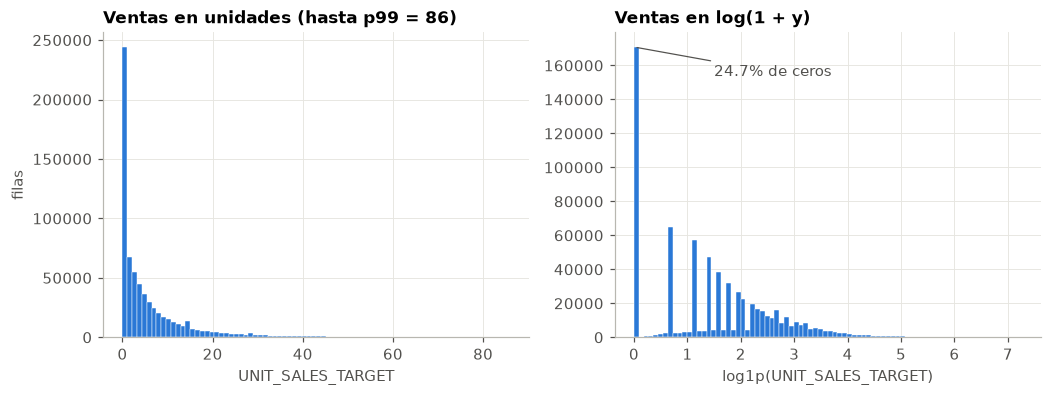

Asimetría en unidades: 8.3 | en log1p: 0.47


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
p99 = y.quantile(0.99)
ejes[0].hist(y[y <= p99], bins=80, color=AZUL, edgecolor='white', linewidth=0.3)
ejes[0].set_title(f'Ventas en unidades (hasta p99 = {p99:.0f})')
ejes[0].set_xlabel('UNIT_SALES_TARGET'); ejes[0].set_ylabel('filas')
ejes[1].hist(np.log1p(y), bins=80, color=AZUL, edgecolor='white', linewidth=0.3)
ejes[1].set_title('Ventas en log(1 + y)')
ejes[1].set_xlabel('log1p(UNIT_SALES_TARGET)')
pct_cero = (y == 0).mean()
ejes[1].annotate(f'{pct_cero:.1%} de ceros', xy=(0, (y == 0).sum()), xytext=(1.5, (y == 0).sum() * 0.9),
                 color=TINTA_2, arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8))
fig.savefig(f'{FIGURAS}/eda_distribucion_objetivo.png')
plt.show()
print(f'Asimetría en unidades: {stats.skew(y):.1f} | en log1p: {stats.skew(np.log1p(y)):.2f}')

In [7]:
por_familia = consultar(f'''
    SELECT FAMILY AS "familia", COUNT(*) AS "filas", AVG({OBJETIVO}) AS "media",
           MEDIAN({OBJETIVO}) AS "mediana",
           PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY {OBJETIVO}) AS "p99",
           100 * AVG(IFF({OBJETIVO} = 0, 1, 0)) AS "pct_ceros",
           100 * AVG(IFF(IS_AFTER_LAST_SALE, 1, 0)) AS "pct_tras_ultima_venta",
           100 * AVG(IFF({OBJETIVO} <> ROUND({OBJETIVO}), 1, 0)) AS "pct_fraccionarias",
           100 * AVG(IFF(ONPROMOTION, 1, 0)) AS "pct_promocion"
    FROM {OBT} GROUP BY 1 ORDER BY 2 DESC''').set_index('familia').astype(float)
por_familia

,filas,media,mediana,p99,pct_ceros,pct_tras_ultima_venta,pct_fraccionarias,pct_promocion
familia,,,,,,,,
PRODUCE,"3,840,378.0000",12.3809,4.8840,120.3150,23.8829,5.4320,35.6482,13.5033
DAIRY,"3,613,387.0000",5.1672,3.0000,37.0000,22.3232,3.7331,0.0000,13.2694
BREAD/BAKERY,"1,717,419.0000",6.4882,3.0000,53.0559,22.0154,3.1267,0.4931,10.7686
DELI,"1,418,301.0000",4.4722,2.0000,36.0000,22.8162,2.9875,6.0522,18.9328
MEATS,"765,804.0000",9.8348,3.6830,94.2065,20.8596,3.7793,77.8563,15.0659
POULTRY,"707,772.0000",11.2461,4.5540,101.6769,27.5488,6.2804,72.2173,11.0842
EGGS,"490,555.0000",8.1748,3.0000,83.0000,18.8878,2.1694,0.0000,15.1225
PREPARED FOODS,"371,672.0000",5.6223,1.0000,58.9630,49.6241,28.0411,3.5424,5.1021
SEAFOOD,"91,714.0000",4.9929,2.0000,35.0000,29.1700,4.0866,21.8156,17.7388


**Lectura.**

- La distribución tiene una masa en cero (23,7 % en la OBT) y una cola larga a la derecha.
  En `log1p` la asimetría prácticamente desaparece.
- **Unidades mixtas.** El 20 % de las cantidades son fraccionarias: MEATS el 78 %, POULTRY el 72 % y
  PRODUCE el 36 %. Esos productos se venden por peso, y DAIRY y EGGS por unidad. Sumar sobrantes o
  faltantes entre familias mezclaría kilos con unidades.
- PREPARED FOODS tiene el 50 % de ceros, y el 28 % de sus filas son posteriores a la última venta
  de la serie: hay productos que dejan de venderse (descontinuados o fuera de surtido).

## 4. Valores atípicos: IQR (diagrama de caja) y Z-score (≥ 3 desviaciones)

Se aplican los dos criterios a la escala original y a `log1p`, en tres niveles: global, por familia y
dentro de cada serie (z calculado con la media y desviación de la propia serie).

In [8]:
def atipicos_iqr(v):
    q1, q3 = v.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)


def atipicos_z(v):
    return np.abs((v - v.mean()) / v.std()) >= 3


log_y = np.log1p(y)
media_serie = log_y.groupby([ventas[c] for c in SERIE]).transform('mean')
desv_serie = log_y.groupby([ventas[c] for c in SERIE]).transform('std')
tabla_atipicos = pd.DataFrame({
    'IQR global (%)': [100 * atipicos_iqr(y).mean(), 100 * atipicos_iqr(log_y).mean()],
    'Z>=3 global (%)': [100 * atipicos_z(y).mean(), 100 * atipicos_z(log_y).mean()],
    'IQR por familia (%)': [100 * y.groupby(ventas['FAMILY']).transform(lambda v: atipicos_iqr(v)).mean(),
                            100 * log_y.groupby(ventas['FAMILY']).transform(lambda v: atipicos_iqr(v)).mean()],
}, index=['unidades', 'log1p'])
tabla_atipicos.loc['log1p', 'Z>=3 dentro de la serie (%)'] = 100 * ((log_y - media_serie).abs() / desv_serie >= 3).mean()
tabla_atipicos

,IQR global (%),Z>=3 global (%),IQR por familia (%),Z>=3 dentro de la serie (%)
unidades,9.6659,1.6591,8.8793,NaN
log1p,0.3951,0.3954,0.3831,0.6308


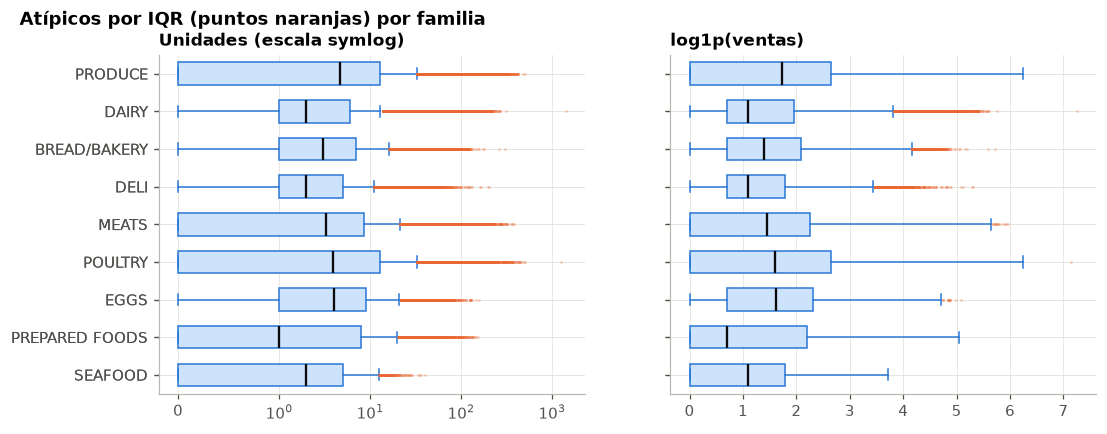

,fecha,tienda,producto,familia,ventas
0,2016-10-07,39,1976284,MEATS,"89,440.0000"
1,2016-10-13,12,584126,MEATS,"11,533.0000"
2,2017-03-03,11,1960892,PRODUCE,"9,796.0000"
3,2016-08-17,39,1976284,MEATS,"5,333.0000"
4,2016-11-11,51,1239986,POULTRY,"5,069.0000"


In [9]:
orden = por_familia.index.tolist()
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
estilo = dict(orientation='horizontal', widths=0.6, patch_artist=True, showfliers=True,
              boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL), medianprops=dict(color=TINTA, lw=1.5),
              whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
              flierprops=dict(marker='o', markersize=2, markerfacecolor=NARANJA, markeredgecolor='none', alpha=0.25))
ejes[0].boxplot([y[ventas['FAMILY'] == f] for f in orden], tick_labels=orden, **estilo)
ejes[0].set_xscale('symlog', linthresh=1); ejes[0].set_title('Unidades (escala symlog)')
ejes[1].boxplot([log_y[ventas['FAMILY'] == f] for f in orden], tick_labels=orden, **estilo)
ejes[1].set_title('log1p(ventas)')
ejes[0].invert_yaxis()
fig.suptitle('Atípicos por IQR (puntos naranjas) por familia', x=0.01, ha='left', fontweight='bold')
fig.savefig(f'{FIGURAS}/eda_boxplot_familias.png')
plt.show()

consultar(f'''SELECT DATE AS "fecha", STORE_NBR AS "tienda", ITEM_NBR AS "producto", FAMILY AS "familia",
                     {OBJETIVO} AS "ventas"
              FROM {OBT} ORDER BY {OBJETIVO} DESC LIMIT 5''')

**Lectura.**

- En unidades, el IQR marca alrededor del 10 % de las filas como atípicas. No son errores: es la
  forma normal de una distribución de conteos con cola larga.
- En `log1p` los atípicos bajan a ~0,4 % por cualquiera de los dos criterios, y a ~0,6 % dentro de
  cada serie.
- El máximo de la OBT (89.440 unidades, tienda 39, MEATS) ya se revisó en el PSet 2: no hay
  evidencia de error, puede ser una compra mayorista, y se conserva.
- **Consecuencia:** no se eliminan ni recortan filas. Se modela `log1p(y)`, lo que acota la
  influencia de la cola sin perder los picos reales, y la métrica técnica es RMSLE: un error
  relativo, no dominado por unas pocas ventas enormes.

## 5. Relación entre el objetivo y las características

**¿Pearson o Spearman? Spearman.** El objetivo no es normal: tiene una masa en cero, asimetría de
8,3 en la muestra (1.597 en la OBT) y atípicos en unidades. Además, las relaciones esperadas son
**monótonas** (más ventas pasadas → más ventas futuras), no necesariamente lineales. Spearman trabaja
con rangos, así que es invariante a `log1p` y robusto a la cola. Pearson, en cambio, mide solo
asociación lineal y depende de la escala: las series grandes y los picos dominan la covarianza.
La sección 5.1 lo muestra con los mismos datos.

Para explorar la memoria de las series se construyen aquí rezagos **temporales y desplazados al
menos 16 días** (el horizonte). Son exploratorios: las features definitivas se construyen en
`src/pipeline.py` (notebook 02).

In [10]:
por_serie = ventas.groupby(SERIE)[OBJETIVO]
exploracion = pd.DataFrame({
    'venta_lag_16': por_serie.shift(16),
    'venta_lag_21': por_serie.shift(21),
    'venta_lag_28': por_serie.shift(28),
    'media_28_desde_16': por_serie.transform(lambda s: s.shift(16).rolling(28, min_periods=7).mean()),
    'frac_ceros_28_desde_16': por_serie.transform(lambda s: (s.shift(16) == 0).rolling(28, min_periods=7).mean()),
})
tienda_dia = ventas.drop_duplicates(['STORE_NBR', 'DATE']).set_index(['STORE_NBR', 'DATE'])['TRANSACTIONS_OBSERVED']
tienda_dia_16 = tienda_dia.groupby(level=0).shift(16).rename('transacciones_lag_16')
exploracion['transacciones_lag_16'] = ventas.join(tienda_dia_16, on=['STORE_NBR', 'DATE'])['transacciones_lag_16']

CANDIDATAS = {
    'ONPROMOTION': 'conocida', 'DAY_OF_WEEK_ISO': 'conocida', 'IS_WEEKEND': 'conocida',
    'IS_HOLIDAY': 'conocida', 'IS_PAYDAY_PROXY': 'conocida', 'DAY_OF_MONTH': 'conocida', 'MONTH': 'conocida',
    'venta_lag_16': 'conocida', 'venta_lag_21': 'conocida', 'venta_lag_28': 'conocida',
    'media_28_desde_16': 'conocida', 'frac_ceros_28_desde_16': 'conocida', 'transacciones_lag_16': 'conocida',
    'TRANSACTIONS_OBSERVED': 'no disponible', 'OIL_PRICE_PREPARED': 'no disponible',
}
datos_corr = pd.concat([ventas[[OBJETIVO]], ventas[[c for c in CANDIDATAS if c in ventas]].astype(float),
                        exploracion], axis=1)
filas = []
for c, disponibilidad in CANDIDATAS.items():
    par = datos_corr[[OBJETIVO, c]].dropna()
    filas.append({'variable': c, 'disponibilidad': disponibilidad, 'filas': len(par),
                  'spearman': stats.spearmanr(par[OBJETIVO], par[c]).statistic,
                  'pearson': stats.pearsonr(par[OBJETIVO], par[c]).statistic})
correlaciones = pd.DataFrame(filas).sort_values('spearman', key=abs, ascending=False).reset_index(drop=True)
correlaciones

,variable,disponibilidad,filas,spearman,pearson
0,media_28_desde_16,conocida,648950,0.7525,0.8387
1,venta_lag_21,conocida,650950,0.6597,0.8003
2,venta_lag_28,conocida,636950,0.6528,0.7964
3,venta_lag_16,conocida,660950,0.6336,0.7196
4,frac_ceros_28_desde_16,conocida,680950,-0.6177,-0.2523
5,TRANSACTIONS_OBSERVED,no disponible,692886,0.3175,0.2802
6,transacciones_lag_16,conocida,667010,0.2814,0.2434
7,ONPROMOTION,conocida,692950,0.2080,0.0982
8,IS_WEEKEND,conocida,692950,0.0749,0.0536
9,DAY_OF_WEEK_ISO,conocida,692950,0.0523,0.0408


### 5.1 Pearson frente a Spearman

Pearson falla en las dos direcciones, según la variable:

- **Sobreestima los rezagos.** Da 0,80 contra 0,66 de Spearman, porque las series de alto volumen y
  los picos concentran la covarianza: una serie que vende 100 diarias "se correlaciona consigo misma"
  con mucho peso. Al aplicar `log1p` baja hacia Spearman.
- **Subestima la fracción de ceros.** Da −0,25 contra −0,62 de Spearman (tabla anterior): la
  relación es fuerte y monótona, pero no lineal.

Spearman, invariante a transformaciones monótonas, no depende de esas decisiones de escala.

In [11]:
comparacion = []
for c in ['venta_lag_21', 'media_28_desde_16', 'transacciones_lag_16']:
    par = datos_corr[[OBJETIVO, c]].dropna()
    comparacion.append({'variable': c,
                        'pearson (unidades)': stats.pearsonr(par[OBJETIVO], par[c]).statistic,
                        'pearson (log1p)': stats.pearsonr(np.log1p(par[OBJETIVO]), np.log1p(par[c])).statistic,
                        'spearman': stats.spearmanr(par[OBJETIVO], par[c]).statistic})
pd.DataFrame(comparacion)

,variable,pearson (unidades),pearson (log1p),spearman
0,venta_lag_21,0.8003,0.6993,0.6597
1,media_28_desde_16,0.8387,0.7846,0.7525
2,transacciones_lag_16,0.2434,0.3003,0.2814


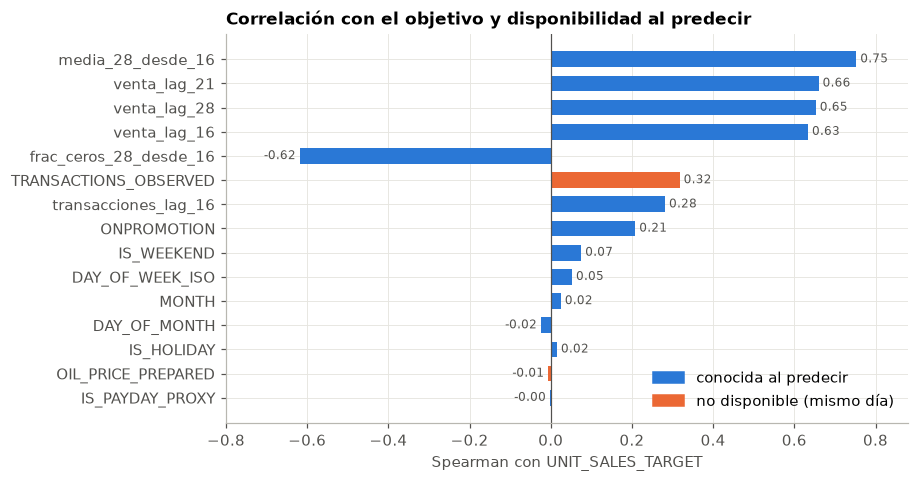

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colores = [AZUL if d == 'conocida' else NARANJA for d in correlaciones['disponibilidad']]
ax.barh(correlaciones['variable'], correlaciones['spearman'], color=colores, height=0.65)
ax.axvline(0, color=TINTA_2, lw=0.8)
ax.invert_yaxis()
ax.set_xlim(-0.8, 0.88)
ax.set_xlabel('Spearman con UNIT_SALES_TARGET')
ax.set_title('Correlación con el objetivo y disponibilidad al predecir')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label='conocida al predecir'),
                   Patch(color=NARANJA, label='no disponible (mismo día)')], loc='lower right', frameon=False)
for i, v in enumerate(correlaciones['spearman']):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right',
            color=TINTA_2, fontsize=8)
fig.savefig(f'{FIGURAS}/eda_spearman_objetivo.png')
plt.show()

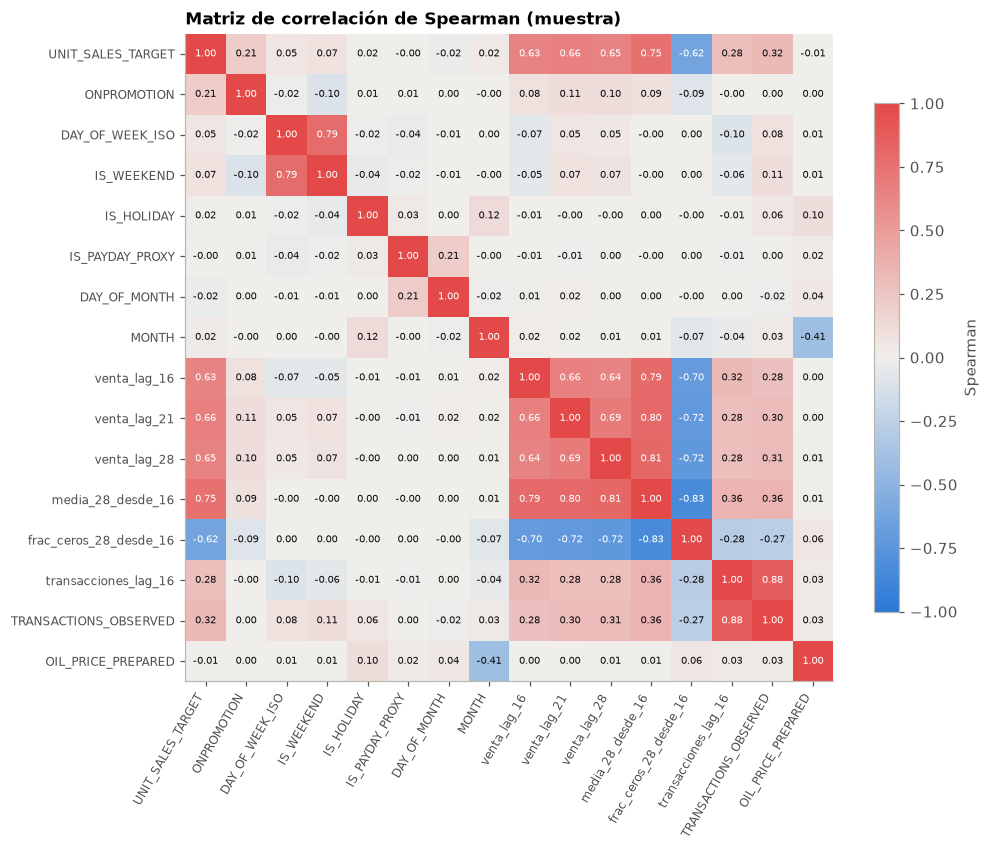

In [13]:
matriz = datos_corr[[OBJETIVO] + list(CANDIDATAS)].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(matriz, cmap=DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz)), matriz.columns, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(matriz)), matriz.columns, fontsize=8)
ax.grid(False)
for i in range(len(matriz)):
    for j in range(len(matriz)):
        ax.text(j, i, f'{matriz.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6.5,
                color='white' if abs(matriz.iloc[i, j]) > 0.6 else TINTA)
fig.colorbar(im, ax=ax, shrink=0.75, label='Spearman')
ax.set_title('Matriz de correlación de Spearman (muestra)')
fig.savefig(f'{FIGURAS}/eda_matriz_spearman.png')
plt.show()

### 5.2 Memoria de las series y estacionalidad semanal

¿Cuánta información queda en la historia **a partir del día 16**, que es la más reciente que el
modelo puede ver? Spearman entre la venta del día *t* y la del día *t − L*, dentro de cada serie.

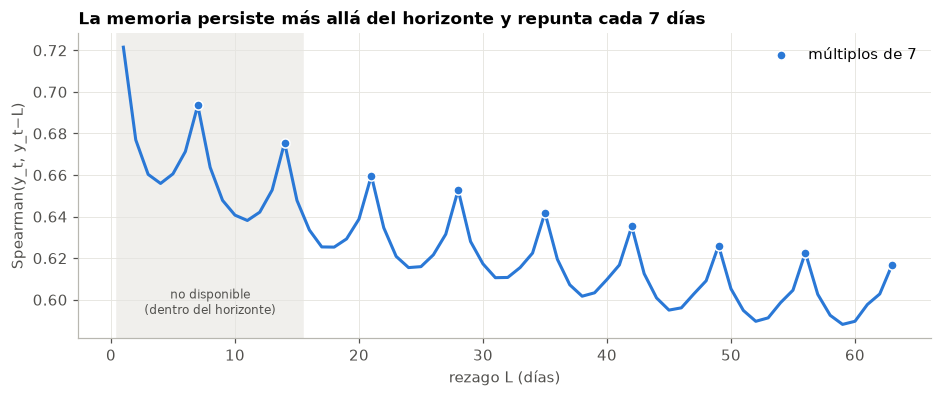

,1,7,14,16,17,20,21,22,28,35
spearman,0.7215,0.6936,0.6756,0.6336,0.6254,0.6388,0.6597,0.6346,0.6528,0.6419


In [14]:
REZAGOS = range(1, 64)
memoria = pd.Series({L: stats.spearmanr(*ventas.assign(lag=por_serie.shift(L))[[OBJETIVO, 'lag']].dropna().T.values).statistic
                     for L in REZAGOS}, name='spearman')
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(memoria.index, memoria.values, color=AZUL, lw=2)
semanales = [L for L in REZAGOS if L % 7 == 0]
ax.scatter(semanales, memoria[semanales], s=36, color=AZUL, edgecolor='white', zorder=3, label='múltiplos de 7')
ax.axvspan(0.5, 15.5, color=GRIS, zorder=0)
ax.text(8, memoria.min() + 0.005, 'no disponible\n(dentro del horizonte)', ha='center', color=TINTA_2, fontsize=8)
ax.set_xlabel('rezago L (días)'); ax.set_ylabel('Spearman(y_t, y_t−L)')
ax.set_title('La memoria persiste más allá del horizonte y repunta cada 7 días')
ax.legend(frameon=False, loc='upper right')
fig.savefig(f'{FIGURAS}/eda_memoria_rezagos.png')
plt.show()
memoria.loc[[1, 7, 14, 16, 17, 20, 21, 22, 28, 35]].to_frame().T

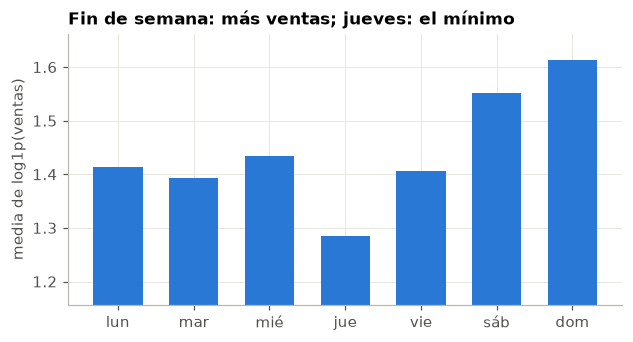

,lun,mar,mié,jue,vie,sáb,dom
media_log1p,1.4140,1.3940,1.4340,1.2850,1.4060,1.5520,1.6140


In [15]:
dia_semana = ventas.assign(log_ventas=log_y).groupby('DAY_OF_WEEK_ISO')['log_ventas'].agg(['mean', 'count'])
dia_semana.index = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(dia_semana.index, dia_semana['mean'], color=AZUL, width=0.65)
ax.set_ylim(dia_semana['mean'].min() * 0.9, dia_semana['mean'].max() * 1.03)
ax.set_ylabel('media de log1p(ventas)')
ax.set_title('Fin de semana: más ventas; jueves: el mínimo')
fig.savefig(f'{FIGURAS}/eda_dia_semana.png')
plt.show()
dia_semana['mean'].round(3).to_frame('media_log1p').T

**Lectura.**

- **Estacionalidad semanal.** La correlación repunta en cada múltiplo de 7. Más allá del horizonte,
  el rezago 21 (mismo día de la semana) supera al 16, al 17 y al 20, y el 28 también es alto.
- **Ventanas que promedian.** La media de 28 días desplazada 16 días supera a cualquier rezago
  individual (≈ 0,75 contra ≈ 0,66): promediar reduce el ruido del día puntual.
- **Variables débiles.** Feriados, quincena y mes tienen correlación casi nula. El petróleo del día
  es ≈ 0 y además no está disponible al predecir.
- **Disponibilidad.** Las transacciones del mismo día correlacionan 0,32, pero no existen en el
  momento de predecir: son una fuga. La versión rezagada 16 días (0,28) sí está disponible.
- **Colinealidad.** La matriz muestra que los rezagos y la media móvil están muy correlacionados
  entre sí (0,64–0,81), y con la fracción de ceros (−0,70 a −0,83). Para el modelo lineal esto
  justifica la regularización (Ridge). Los árboles no se ven afectados.

### 5.3 Promoción: efecto real y artefacto de la reconstrucción de ceros

En el PSet 2, la promoción de los ceros reconstruidos se imputó como FALSE, porque un NULL habría
revelado que la fila es un cero. Hay que comprobar si FALSE también revela algo.

In [16]:
observadas = ventas[ventas['IS_OBSERVED']]
promo = pd.DataFrame({
    'panel completo': ventas.groupby('ONPROMOTION')[OBJETIVO].median(),
    'solo ventas observadas': observadas.groupby('ONPROMOTION')[OBJETIVO].median(),
}).rename_axis('ONPROMOTION')
print('Mediana de ventas por promoción:'); display(promo)
cruce = pd.crosstab(ventas['ONPROMOTION'], ventas[OBJETIVO] == 0, normalize='index').rename(
    columns={False: 'venta > 0', True: 'venta = 0'})
print('Proporción de ceros según promoción (panel):'); display(cruce)
print('Ceros reconstruidos con promoción TRUE:', int((ventas['IS_IMPUTED_ZERO'] & ventas['ONPROMOTION']).sum()))
media_log_serie = log_y.groupby([ventas[c] for c in SERIE]).transform('mean')
print('Spearman dentro de la serie (log1p centrado) — panel:',
      round(stats.spearmanr(log_y - media_log_serie, ventas['ONPROMOTION']).statistic, 3),
      '| solo observadas:',
      round(stats.spearmanr((log_y - media_log_serie)[ventas['IS_OBSERVED']], observadas['ONPROMOTION']).statistic, 3))

Mediana de ventas por promoción:


,panel completo,solo ventas observadas
ONPROMOTION,,
False,3.0000,5.0000
True,6.0000,6.0000


Proporción de ceros según promoción (panel):


UNIT_SALES_TARGET,venta > 0,venta = 0
ONPROMOTION,,
False,0.7152,0.2848
True,1.0000,0.0000


Ceros reconstruidos con promoción TRUE: 0


Spearman dentro de la serie (log1p centrado) — panel: 0.234 | solo observadas: 0.14


**Lectura.**

- **Efecto real.** La promoción sí está asociada a más ventas: entre las ventas observadas, la
  mediana pasa de 5 a 6 unidades.
- **Efecto inflado.** En el panel completo la mediana pasa de 3 a 6, y la asociación dentro de cada
  serie baja de 0,234 a 0,14 al quitar los ceros reconstruidos. Cerca del 40 % de la señal aparente
  de la promoción viene de la imputación.
- **Artefacto.** En el panel **ninguna** fila con promoción vale cero, por construcción: los ceros
  reconstruidos tienen la promoción imputada como FALSE. El modelo podría aprender la regla
  "con promoción, nunca cero", que es un artefacto de la imputación y no un patrón del negocio.
  En producción, la promoción planificada se conoce para todas las filas, también para las que
  terminarán en cero.
- **Consecuencia:** `ONPROMOTION` del día es candidata, pero con fuga parcial. Se decide en el
  notebook 02 con una prueba con y sin la variable.

### 5.4 Heterogeneidad de escala entre series

                       count   mean     std    min    10%    50%     90%     99%      max
media de la serie 2,000.0000 7.8200 14.9100 0.0000 0.6900 3.5800 17.6700 67.4400 195.1100


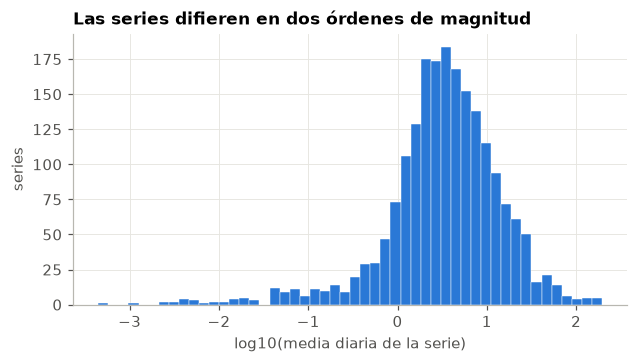

In [17]:
media_por_serie = por_serie.mean()
print(media_por_serie.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(2).to_frame('media de la serie').T.to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(np.log10(media_por_serie[media_por_serie > 0]), bins=50, color=AZUL, edgecolor='white', linewidth=0.3)
ax.set_xlabel('log10(media diaria de la serie)'); ax.set_ylabel('series')
ax.set_title('Las series difieren en dos órdenes de magnitud')
fig.savefig(f'{FIGURAS}/eda_escala_series.png')
plt.show()

## 6. Ceros e intermitencia

Una cuarta parte del objetivo es cero. ¿Es predecible con información disponible antes del corte?

Proporción de ceros hoy según la fracción de días sin venta en la ventana de 28 días que termina 16 días antes:


UNIT_SALES_TARGET,venta > 0,venta = 0,filas
frac_ceros_28_desde_16,,,
0%,0.9418,0.0582,200098
1–25%,0.8471,0.1529,280969
26–50%,0.6323,0.3677,98459
51–75%,0.4275,0.5725,38053
76–100%,0.1131,0.8869,63371


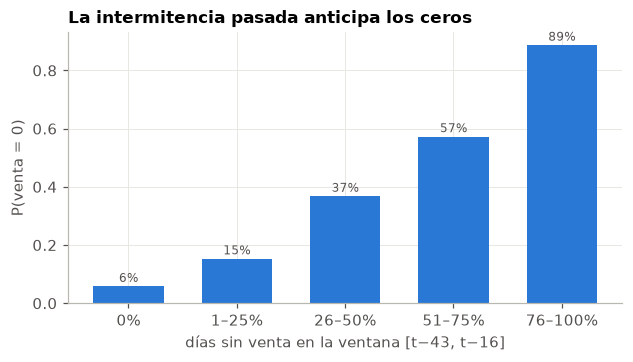

In [18]:
frac = exploracion['frac_ceros_28_desde_16']
validas = frac.notna()
intermitencia = pd.crosstab(pd.cut(frac[validas], [-0.01, 0, 0.25, 0.5, 0.75, 1],
                                   labels=['0%', '1–25%', '26–50%', '51–75%', '76–100%']),
                            (y[validas] == 0), normalize='index').rename(columns={False: 'venta > 0', True: 'venta = 0'})
intermitencia['filas'] = frac[validas].groupby(pd.cut(frac[validas], [-0.01, 0, 0.25, 0.5, 0.75, 1])).size().values
print('Proporción de ceros hoy según la fracción de días sin venta en la ventana de 28 días que termina 16 días antes:')
display(intermitencia)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(intermitencia.index.astype(str), intermitencia['venta = 0'], color=AZUL, width=0.65)
ax.set_xlabel('días sin venta en la ventana [t−43, t−16]'); ax.set_ylabel('P(venta = 0)')
ax.set_title('La intermitencia pasada anticipa los ceros')
for i, v in enumerate(intermitencia['venta = 0']):
    ax.text(i, v + 0.015, f'{v:.0%}', ha='center', color=TINTA_2, fontsize=8)
fig.savefig(f'{FIGURAS}/eda_intermitencia.png')
plt.show()

**Lectura.**

- **Señal de los ceros.** Si en la ventana disponible la serie no vendió ningún día, hoy vende casi
  siempre (~6 % de ceros). Si no vendió más de 3 de cada 4 días, hoy es cero ~89 % de las veces.
- **Consecuencia:** la fracción de días sin venta es una feature derivada directamente de este
  hallazgo. Los ceros se modelan y no se descartan, porque la merma del baseline se produce
  precisamente en esos días.

## 7. ¿Desbalance de clases?

El problema es de **regresión**, no de clasificación, así que no hay clases que balancear. Su
análogo es la **masa en cero** (≈ 24 % de las filas). No se balancea, porque cambiaría la
distribución que el modelo debe reproducir. Lo que sí implica:

1. La métrica debe tratar bien los ceros. RMSLE lo hace, porque `log(1 + 0) = 0`.
2. Las predicciones deben acotarse a ≥ 0.
3. La métrica de negocio se calcula sobre el panel **con** ceros: sin ellos, la merma del baseline
   quedaría subestimada.

## 8. Hallazgos que afectan el modelado

| # | Hallazgo | Evidencia (celda) | Consecuencia en el modelo |
|---|---|---|---|
| 1 | **Objetivo con cola larga** | Mediana 3, p99 79, máximo 89.440, asimetría 1.597 (§2). El IQR marca ~10 % de atípicos en unidades y ~0,4 % en `log1p` (§4) | Entrenar sobre `log1p(y)` y evaluar con **RMSLE** (métrica técnica del PSet 1). No eliminar atípicos (son ventas reales). MAE como complemento en unidades |
| 2 | **Memoria más allá del horizonte, con ciclo semanal** | Spearman: rezago 16 ≈ 0,63; rezago 21 ≈ 0,66 (mismo día de la semana); media de 28 días desplazada 16 ≈ 0,75 (§5.2) | Features de **rezagos ≥ 16 días alineados al día de la semana** (21, 28) y **medias móviles desplazadas 16 días**. Día de la semana como variable. Rezagos 1–15 prohibidos (fuga) |
| 3 | **Los ceros son predecibles por la intermitencia pasada** | 0 % de días sin venta en [t−43, t−16] → 6 % de ceros hoy; 76–100 % → 89 % (§6). PREPARED FOODS: 28 % de filas tras la última venta (§3) | Feature **`frac_ceros_28`** (desplazada 16). Predicciones ≥ 0 y evaluación sobre el panel con ceros |
| 4 | **Escalas muy distintas entre series** | Media diaria por serie: p10 0,69, mediana 3,6, p99 67 (§5.4) | Feature del **nivel histórico de la serie** (calculada solo con datos anteriores al corte), en vez de *one-hot* de 986 productos |
| 5 | **Variables del día que no existen al predecir** | Transacciones del mismo día: Spearman 0,32; petróleo ≈ 0 (§5) | Excluir transacciones y petróleo del mismo día; usar transacciones de la tienda **rezagadas 16 días** |
| 6 | **Promoción con fuga parcial por la imputación de ceros** | 0 ceros con promoción TRUE en el panel; asociación dentro de la serie 0,234 en el panel contra 0,14 solo en ventas observadas (§5.3) | Probar el modelo **con y sin `ONPROMOTION`** antes de aceptarla (notebook 02) |
| 7 | **Unidades mixtas (kilos y piezas)** | 20 % de cantidades fraccionarias; MEATS 78 %, POULTRY 72 % (§3) | Merma y cobertura se reportan como **tasas por familia** y agregadas con ponderación explícita, no sumando kilos con unidades |